## Reducing Large Language Model Size Using Quantization



Modern language models like **BERT** and **LLaMA** feature billions of parameters, causing severe memory constraints and high computational overhead during deployment[cite: 1]. To address this challenge, **quantization** reduces model size by mapping high-precision numerical values (such as 32-bit floating-point, $\text{FP32}$) to lower-bit representations (such as 8-bit integers, $\text{INT8}$).

Quantization approaches generally fall into two main categories:

* **Post-Training Quantization (PTQ):** Converts a fully pre-trained model's weights directly into lower precision using a small calibration dataset, offering a fast and resource-efficient conversion without retraining.
* **Quantization-Aware Training (QAT):** Simulates quantization noise during the training or fine-tuning process, allowing the model parameters to adapt and minimize accuracy degradation.

In the subsequent sections of this notebook, we will measure the exact memory savings achieved through these methods and discuss the inherent accuracy trade-offs involved in lowering bit precision.

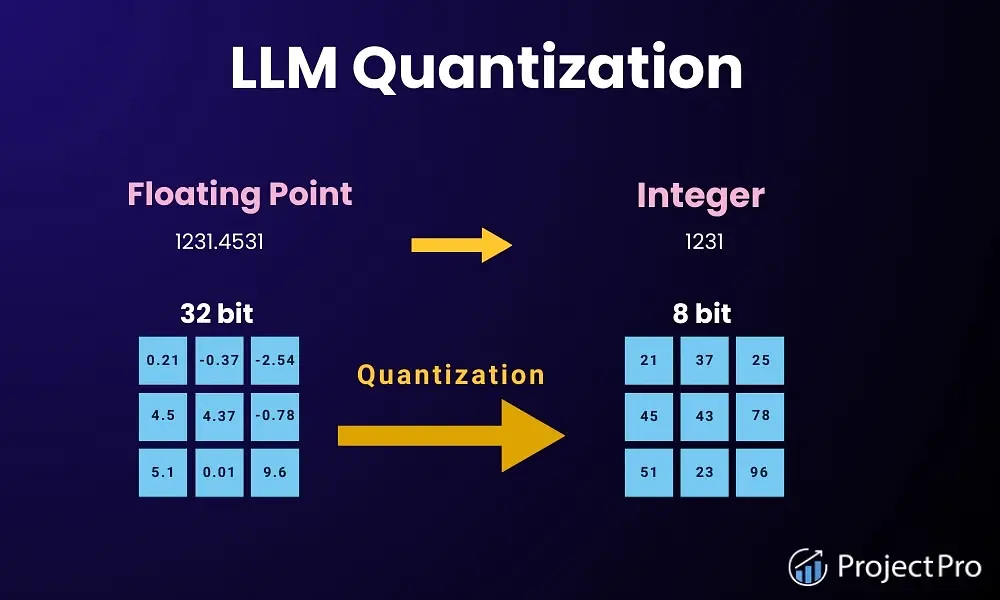

### How Quantization Works

Quantization converts high-precision floating-point values into low-precision integer values using a mathematical mapping function.

A standard **affine (asymmetric) quantizer** maps a floating-point value $x$ to its low-precision integer representation $q$ using a scale factor $s$ and a zero-point $z$:

$$q = \text{round}\left(\frac{x}{s}\right) + z$$

* **Scale ($s$):** A positive real number that determines the step size of the quantization grid.
* **Zero-point ($z$):** An integer that maps the real value $0.0$ to a quantized integer, ensuring exact representation of zero.

To reconstruct an approximation $\hat{x}$ of the original value from the quantized integer $q$, we use the **dequantization** formula:

$$\hat{x} = s(q - z)$$

Because the rounding operation causes a slight loss of precision, the reconstructed value $\hat{x}$ is not identical to $x$. The difference between the original floating-point value and the reconstructed value is defined as the **quantization error**:

$$\text{Error} = x - \hat{x}$$

### Advanced Quantization Techniques & LLM Approaches

Beyond static quantization, modern large language models leverage dynamic techniques and specialized algorithms designed to preserve performance at ultra-low bit rates.

#### 1. Dynamic Quantization
* **Mechanism:** Weights are quantized offline beforehand, while activation scales are computed dynamically on-the-fly during inference.
* **Use Case:** Highly convenient and effective for memory-bandwidth bound layers, particularly standard linear (dense) layers in Transformer architectures.

#### 2. Specialized LLM Quantization Methods
Standard uniform quantization can cause severe quality degradation when applied to sub-8-bit LLMs. To prevent accuracy loss, modern approaches utilize specialized quantization schemes:

* **8-bit Methods (e.g., LLM.int8()):** Isolates feature outliers in activations into a high-precision floating-point matrix while quantizing the remaining $99.9\%$ of weights to 8-bit integers.
* **GPTQ (Generalized Post-Training Quantization):** A second-order PTQ method that uses Hessian matrix information to update remaining unquantized weights column-by-column, minimizing reconstruction error.
* **AWQ (Activation-aware Weight Quantization):** Protects the top $1\%$ of salient channels based on activation magnitudes rather than weight magnitudes alone.
* **4-bit NormalFloat (NF4) & QLoRA:** A data type theoretically optimal for normally distributed weights, allowing models to be loaded into 4-bit memory space and fine-tuned using Low-Rank Adaptations (LoRA).

## Code example: basic quantization math

In [5]:
import numpy as np
import matplotlib.pyplot as plt

weights = np.array([-1.20, -0.65, -0.10, 0.15, 0.72, 1.35], dtype=np.float32)

qmin, qmax = -128, 127
scale = max(abs(weights.min()), abs(weights.max())) / qmax
zero_point = 0

quantized = np.clip(np.round(weights / scale), qmin, qmax).astype(np.int8)
dequantized = quantized.astype(np.float32) * scale
error = weights - dequantized

print("Original FP32 weights:", weights)
print("INT8 values:", quantized)
print("Recovered values:", dequantized)
print("Mean absolute error:", np.mean(np.abs(error)))

Original FP32 weights: [-1.2  -0.65 -0.1   0.15  0.72  1.35]
INT8 values: [-113  -61   -9   14   68  127]
Recovered values: [-1.201181   -0.6484252  -0.09566929  0.1488189   0.72283465  1.35      ]
Mean absolute error: 0.0018503666


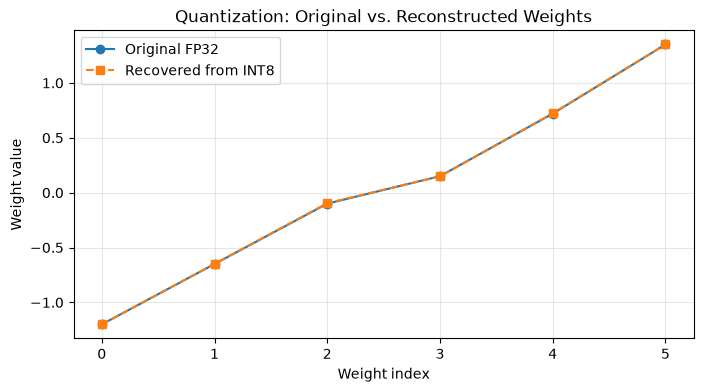

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(weights, "o-", label="Original FP32")
plt.plot(dequantized, "s--", label="Recovered from INT8")
plt.title("Quantization: Original vs. Reconstructed Weights")
plt.xlabel("Weight index")
plt.ylabel("Weight value")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Code example: memory graph

,Precision,Estimated weight memory (GiB)
0,FP32,26.077032
1,FP16,13.038516
2,INT8,6.519258
3,INT4,3.259629


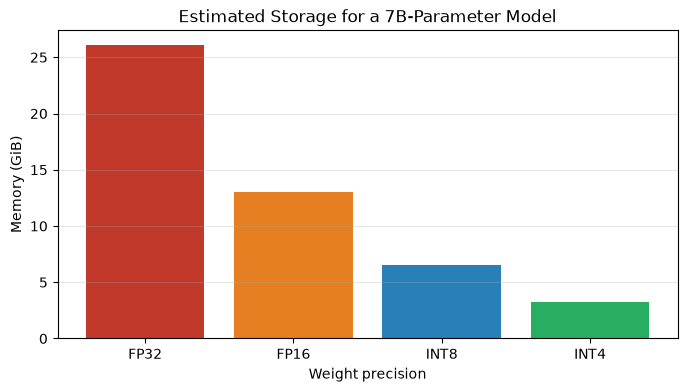

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

parameters = 7_000_000_000  # Example: 7B-parameter LLM

formats = {
    "FP32": 32,
    "FP16": 16,
    "INT8": 8,
    "INT4": 4
}

memory_gb = {
    name: parameters * bits / 8 / (1024**3)
    for name, bits in formats.items()
}

df = pd.DataFrame({
    "Precision": list(memory_gb.keys()),
    "Estimated weight memory (GiB)": list(memory_gb.values())
})

display(df)

plt.figure(figsize=(8, 4))
plt.bar(df["Precision"], df["Estimated weight memory (GiB)"],
        color=["#c0392b", "#e67e22", "#2980b9", "#27ae60"])
plt.title("Estimated Storage for a 7B-Parameter Model")
plt.xlabel("Weight precision")
plt.ylabel("Memory (GiB)")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Finally , LLM quantization trial

In [8]:

%pip install -q transformers bitsandbytes accelerate

Note: you may need to restart the kernel to use updated packages.


In [9]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

# 1. Define a lightweight LLM model (SmolLM-135M or Qwen2.5-0.5B)
model_id = "HuggingFaceTB/SmolLM-135M"

# 2. Load model in standard FP16 (Unquantized)
model_fp16 = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)

memory_fp16 = model_fp16.get_memory_footprint() / (1024 ** 2)
print(f"FP16 Model Memory Footprint: {memory_fp16:.2f} MB")

# 3. Configure 4-bit Quantization 
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

# Load model in quantized 4-bit mode
model_4bit = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto"
)

memory_4bit = model_4bit.get_memory_footprint() / (1024 ** 2)
print(f"4-bit Quantized Model Memory Footprint: {memory_4bit:.2f} MB")

# 4. Compute and print memory reduction percentage
savings = ((memory_fp16 - memory_4bit) / memory_fp16) * 100
print(f"\n--- Quantization Summary ---")
print(f"Memory Saved: {savings:.2f}%")
print(f"Compression Factor: {memory_fp16 / memory_4bit:.2f}x smaller")

c:\Desktop\desktop\Summer interns\Cellula NLP\MeRAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Desktop\desktop\Summer interns\Cellula NLP\MeRAG\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mocam\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM-135M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Pytho

FP16 Model Memory Footprint: 256.57 MB


Loading weights: 100%|██████████| 272/272 [00:01<00:00, 173.82it/s]

4-bit Quantized Model Memory Footprint: 104.69 MB

--- Quantization Summary ---
Memory Saved: 59.20%
Compression Factor: 2.45x smaller
